# 🤖 MINI PROJECT: CHATBOT FAQ BAHASA INDONESIA
## Komparasi Chatbot Retrieval (TF-IDF + Cosine Similarity) vs. Neural Network (Intent Classifier Bi-LSTM/GRU)
**Tugas Lanjutan Pertemuan 10 & 11 — Pemrosesan Bahasa Alami (NLP)**  
**Kode Mata Kuliah:** NINF236023 - INTNINF236026  

---

### 🏛️ Informasi Akademik
* **Program Studi / Jurusan** : Teknik Informatika / S1 Pendidikan Teknik Informatika
* **Dosen Pengampu** :
  1. Prof. Aji Prasetya Wibawa, S.T., M.M.T., Ph.D.
  2. M. Zainal Arifin, S.Si., M.Kom., Ph.D.
* **Mentor Asisten** :
  1. Agung Bella Putra Utama
  2. Fadia Irsania Putri

---

### 👥 Anggota Kelompok & Pembagian Tugas (Job Desk)

| No | NIM | Nama Mahasiswa | Peran & Tanggung Jawab Utama |
| :-: | :---: | :--- | :--- |
| **1** | `240535601034` | **ALBI ADWITIYA CHANDRA** | **Data Preparation & Preprocessing:**<br>• Pengumpulan & kurasi dataset FAQ.<br>• Text cleaning, case folding, normalisasi kata tidak baku/slang, pembersihan kata pengisi (*filler words*).<br>• Memastikan pembagian data (*stratified split* train-val-test) identik dengan `SEED` yang sama untuk kedua model. |
| **2** | `240535610197` | **INDAH HARIYANTI** | **Pengembang Model 1 (Retrieval-based):**<br>• Ekstraksi fitur teks menggunakan TF-IDF (*unigram + bigram*, sublinear TF).<br>• Implementasi pencocokan kemiripan pertanyaan berbasis *Cosine Similarity*.<br>• Mekanisme pemetaan respons retrieval dan thresholding Model 1. |
| **3** | `240535600363` | **ASYAM SAKHI MAULANA** | **Pengembang Model 2 (Neural Network Intent Classifier):**<br>• Pipeline tokenisasi, pembuatan kamus kata (*vocabulary*), padding, dan encoding sequence.<br>• Arsitektur Deep Learning: Embedding $\rightarrow$ Bidirectional RNN (LSTM / GRU) $\rightarrow$ Dropout $\rightarrow$ Dense Softmax.<br>• Training loop dengan Early Stopping, optimasi model, dan confidence thresholding. |
| **4** | `240535604624` | **CHRISTIAN LIONEL DAUN DARMA** | **Evaluator & Metrik Kuantitatif:**<br>• Evaluasi performa model pada data uji (*test set*).<br>• Pengukuran metrik: Akurasi intent, Precision, Recall, dan Macro F1-score.<br>• Visualisasi Confusion Matrix dan F1-score per-intent.<br>• Komparasi efisiensi komputasi: waktu training (*training time*) dan waktu respons (*inference latency per query*). |
| **5** | `240535607403` | **AGUSTINUS MARIA AGUNG HERIYANTO** | **Analis Error, Variasi Kalimat & Robustness:**<br>• Pengujian ketahanan model terhadap kalimat bervariasi (kalimat panjang vs pendek, singkatan, susunan baru).<br>• Analisis kata di luar kosakata (*Out-of-Vocabulary* / OOV).<br>• Evaluasi kasus prediksi benar dan salah (*qualitative error analysis*).<br>• Analisis penanganan skor kepercayaan rendah (*fallback mechanism*). |

---

### 🎯 Tujuan & Aspek Komparasi Proyek
Proyek ini membandingkan kelebihan dan kekurangan dari dua paradigma chatbot (Information Retrieval vs. Deep Learning Sequence Classification) berdasarkan:
1. **Akurasi Pemilihan Intent / Respons**
2. **Precision, Recall, dan F1-score (Macro & Per-intent)**
3. **Kemampuan Menangani Variasi Kalimat** (kalimat formal/panjang vs kalimat singkat/slang)
4. **Waktu Training (Training Time)**
5. **Waktu Respons per Kalimat (Inference Latency in ms)**
6. **Visualisasi Confusion Matrix**
7. **Contoh Prediksi Benar dan Salah**
8. **Analisis Error** (termasuk OOV dan penanganan *low-confidence fallback*)

---

## 1. Setup

In [ ]:
import os, re, time, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

SEED = 42          # seed yang sama untuk SEMUA kelompok agar split data identik
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)

# Nama berkas dataset utama
DATASET_NAME = "IndoHealth_NLP_NCD_Instruct_QA_Sample.csv"

# Cek keberadaan file di sesi Colab / folder kerja
# Jika belum ada, munculkan tombol upload interaktif
if not os.path.exists(DATASET_NAME):
    try:
        from google.colab import files
        print(f"File '{DATASET_NAME}' belum ada di sesi Google Colab.")
        print("Silakan klik tombol 'Choose Files' di bawah untuk mengunggah dataset:")
        uploaded = files.upload()
    except ImportError:
        # Fallback jika dijalankan di lokal
        for candidate in [
            '01_DATASET/IndoHealth_NLP_NCD_Instruct_QA_Sample.csv',
            'Pertemuan 11/IndoHealth_NLP_NCD_Instruct_QA_Sample.csv'
        ]:
            if os.path.exists(candidate):
                DATASET_NAME = candidate
                break

DATASET_PATH = DATASET_NAME
OUTPUT_PATH = "03_HASIL_PREPROCESSING"
os.makedirs(OUTPUT_PATH, exist_ok=True)

print("\n" + "="*50)
print("Persiapan notebook berhasil!")
print("SEED         :", SEED)
print("Dataset path :", DATASET_PATH)
print("="*50)


File 'IndoHealth_NLP_NCD_Instruct_QA_Sample.csv' belum ada di sesi Google Colab.
Silakan klik tombol 'Choose Files' di bawah untuk mengunggah dataset:


Saving IndoHealth_NLP_NCD_Instruct_QA_Sample.csv to IndoHealth_NLP_NCD_Instruct_QA_Sample.csv

Persiapan notebook berhasil!
SEED         : 42
Dataset path : IndoHealth_NLP_NCD_Instruct_QA_Sample.csv


## 2. Dataset

### 📄 Deskripsi & Karakteristik Dataset\n
Dataset yang digunakan dalam mini project ini adalah **IndoHealth (Non-Communicable Diseases / NCD Instruct QA Sample)**, korpus tanya-jawab klinis berbahasa Indonesia seputar penyakit tidak menular kronis.\n
\n
**Karakteristik Korpus:**\n
- **Total Data:** 200 sampel instruksi pertanyaan dan jawaban klinis.\n
- **Distribusi Kelas Target (disease_tag):**\n
  1. **Diabetes** (119 sampel): Pertanyaan seputar kadar gula darah, komplikasi neuropati/luka, diet rendah karbohidrat, dan insulin.\n
  2. **Comorbidity** (48 sampel): Kondisi pasien yang memiliki penyakit penyerta secara bersamaan (kombinasi diabetes melitus tipe-2 dan hipertensi, serta risiko gagal ginjal/jantung).\n
  3. **Hypertension** (33 sampel): Pertanyaan mengenai tekanan darah sistolik/diastolik tinggi, pembatasan asupan natrium/garam, pencegahan stroke, dan obat antihipertensi.\n
- **Struktur Kolom:** system (prompt role), instruction (pertanyaan pasien), output (jawaban dokter/perawat), pmid (rujukan literatur), disease_tag (label kelas target).\n

In [ ]:
#LOAD DATASET & EXPLORATION


df = pd.read_csv(DATASET_PATH)

print("Ukuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nJumlah missing values:")
print(df.isnull().sum())

print("\nJumlah data duplikat:")
print(df.duplicated(
    subset=['instruction', 'output']
).sum())

print("\nDistribusi kategori penyakit:")
print(df['disease_tag'].value_counts())

print("\nContoh dataset:")
display(df.head())


Ukuran dataset: (200, 5)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   system       200 non-null    object
 1   instruction  200 non-null    object
 2   output       200 non-null    object
 3   pmid         200 non-null    int64 
 4   disease_tag  200 non-null    object
dtypes: int64(1), object(4)
memory usage: 7.9+ KB

Jumlah missing values:
system         0
instruction    0
output         0
pmid           0
disease_tag    0
dtype: int64

Jumlah data duplikat:
0

Distribusi kategori penyakit:
disease_tag
Diabetes        119
Comorbidity      48
Hypertension     33
Name: count, dtype: int64

Contoh dataset:


,system,instruction,output,pmid,disease_tag
0,Anda adalah Perawat Edukator Klinis dan Spesialis Triase Telemedis yang ahli dalam manajemen NCD.,"Ners, penglihatan saya belakangan ini makin buram dan berbayang. Saya memang punya riwayat kencing manis yang sudah ...",Halo. Keluhan penglihatan buram pada penderita kencing manis sering kali berkaitan dengan penumpukan cairan atau pem...,40576850,Diabetes
1,Anda adalah Perawat Edukator Klinis dan Spesialis Triase Telemedis yang ahli dalam manajemen NCD.,"Ners, mau konsultasi. Saya kan ada riwayat kencing manis, belakangan ini air kencing saya kok makin berbusa ya? Teru...",Halo. Gejala air kencing berbusa dan adanya pembengkakan (sembab) pada anggota tubuh memang perlu diwaspadai sebagai...,41497482,Comorbidity
2,Anda adalah Perawat Edukator Klinis dan Spesialis Triase Telemedis yang ahli dalam manajemen NCD.,"Sus, saya kan punya riwayat gula darah tinggi. Belakangan ini kok boyok saya sering pegal linu dan tengkuk rasanya k...","Halo. Ya, keluhan pegal pada boyok (punggung bawah) dan tengkuk kaku memang berisiko lebih tinggi terjadi pada pende...",42169123,Diabetes
3,Anda adalah Perawat Edukator Klinis dan Spesialis Triase Telemedis yang ahli dalam manajemen NCD.,"Sus, anggota keluarga saya kan punya riwayat hipertensi paru dan sebentar lagi mau menjalani operasi jantung. Saya s...","Halo. Pada pasien dengan riwayat hipertensi paru yang menjalani operasi jantung, pemberian obat milrinone melalui in...",40762643,Hypertension
4,Anda adalah Perawat Edukator Klinis dan Spesialis Triase Telemedis yang ahli dalam manajemen NCD.,"Ners, mata saya kok rasanya makin lama makin burem ya? Padahal saya emang ada riwayat kencing manis dari beberapa ta...",Halo Bapak/Ibu. Keluhan penglihatan kabur atau burem pada penderita kencing manis (diabetes) memang perlu mendapat p...,42117585,Diabetes


## 3. Preprocessing dasar (sama untuk kedua model)

Langkah: huruf kecil, hapus tanda baca, normalisasi kata tidak baku, dan buang kata pengisi (kak, dong, ya, ...).

In [ ]:
# ==============================================================================
# BAGIAN 3: PREPROCESSING DASAR (SAMA UNTUK KEDUA MODEL)
# Penanggung Jawab: Albi Adwitiya Chandra (240535601034)
# ==============================================================================

# 1. DATA CURATION
# Menghapus missing value pada instruksi, output, maupun disease_tag
df = df.dropna(subset=['instruction', 'output', 'disease_tag']).copy()

# Menghapus pasangan instruksi dan jawaban duplikat
df = df.drop_duplicates(subset=['instruction', 'output']).reset_index(drop=True)

# Membuat ulang ID unik
if 'row_id' in df.columns:
    df = df.drop(columns=['row_id'])
df.insert(0, 'row_id', range(len(df)))

print(f"Kurasi dataset selesai! Jumlah data bersih: {len(df)}")


# 2. FUNGSI TEXT CLEANING & CASE FOLDING
def text_cleaning(text):
    text = str(text).lower()                         # Case folding ke huruf kecil
    text = re.sub(r'http\S+|www\S+', '', text)        # Hapus URL/Link
    text = re.sub(r'[^\w\s]', ' ', text)             # Hapus tanda baca/simbol
    text = re.sub(r'\s+', ' ', text).strip()         # Rapikan spasi berlebih
    return text


# 3. FUNGSI SLANG NORMALIZATION (Kamus Kata Percakapan ke Baku)
normalisasi_kata = {
    'gak': 'tidak', 'ga': 'tidak', 'nggak': 'tidak', 'enggak': 'tidak', 'ngga': 'tidak', 'engga': 'tidak',
    'gimana': 'bagaimana', 'gmn': 'bagaimana', 'bgmn': 'bagaimana',
    'udah': 'sudah', 'udh': 'sudah', 'blm': 'belum', 'belom': 'belum',
    'aja': 'saja', 'kayak': 'seperti', 'kalo': 'kalau', 'karna': 'karena', 'krn': 'karena',
    'pake': 'pakai', 'bgt': 'banget', 'dgn': 'dengan', 'sy': 'saya', 'yg': 'yang'
}

def normalisasi(text):
    words = text.split()
    return ' '.join([normalisasi_kata.get(w, w) for w in words])


# 4. FUNGSI FILLER WORDS REMOVAL (Kata Pengisi Percakapan)
filler_words = {'hmm', 'emm', 'eee', 'anu', 'ya', 'dong', 'kak', 'sih', 'deh', 'nih'}

def remove_filler_words(text):
    words = text.split()
    return ' '.join([w for w in words if w not in filler_words])


# 5. PIPELINE PREPROCESSING TERPADU
def preprocess(text):
    """Fungsi tunggal yang dipakai untuk training dan prediksi kalimat baru."""
    return remove_filler_words(normalisasi(text_cleaning(text)))


# 6. PENERAPAN PREPROCESSING PADA DATASET
df['instruction_clean'] = df['instruction'].apply(preprocess)
df['output_clean'] = df['output'].apply(preprocess)


# 7. STANDARISASI KOLOM (JEMBATAN UNTUK MODEL 1, MODEL 2, & EVALUASI)
df['pertanyaan'] = df['instruction']
df['jawaban']    = df['output']
df['intent']     = df['disease_tag']          # Target klasifikasi
df['bersih']     = df['instruction_clean']    # Teks input terproses

# Daftar kelas intent unik
CLASSES = sorted(df['intent'].unique().tolist())

# Template balasan default per kategori (untuk demo chatbot & fallback di Bagian 12)
RESPONS = {
    "Diabetes": (
        "Informasi Diabetes: Perhatikan kadar glukosa darah secara berkala, batasi konsumsi "
        "karbohidrat sederhana dan gula, perbanyak aktivitas fisik, serta konsultasikan "
        "jadwal dan dosis obat antidiabetes/insulin ke dokter spesialis."
    ),
    "Hypertension": (
        "Informasi Hipertensi: Jaga kestabilan tekanan darah dengan membatasi asupan garam (natrium), "
        "mengelola stres, menjaga berat badan ideal, dan mematuhi konsumsi obat penurun tensi yang diresepkan."
    ),
    "Comorbidity": (
        "Informasi Komorbiditas: Pasien dengan kondisi diabetes dan hipertensi bersamaan memerlukan "
        "penanganan terpadu untuk mencegah komplikasi kardiovaskular dan penurunan fungsi ginjal. "
        "Sangat disarankan berkonsultasi secara intensif dengan dokter spesialis."
    )
}

print("Daftar Kelas Intent (CLASSES):", CLASSES)
print("Contoh Data Setelah Preprocessing:")
display(df[['pertanyaan', 'bersih', 'intent']].head(3))

Kurasi dataset selesai! Jumlah data bersih: 200
Daftar Kelas Intent (CLASSES): ['Comorbidity', 'Diabetes', 'Hypertension']
Contoh Data Setelah Preprocessing:


,pertanyaan,bersih,intent
0,"Ners, penglihatan saya belakangan ini makin buram dan berbayang. Saya memang punya riwayat kencing manis yang sudah ...",ners penglihatan saya belakangan ini makin buram dan berbayang saya memang punya riwayat kencing manis yang sudah la...,Diabetes
1,"Ners, mau konsultasi. Saya kan ada riwayat kencing manis, belakangan ini air kencing saya kok makin berbusa ya? Teru...",ners mau konsultasi saya kan ada riwayat kencing manis belakangan ini air kencing saya kok makin berbusa terus kaki ...,Comorbidity
2,"Sus, saya kan punya riwayat gula darah tinggi. Belakangan ini kok boyok saya sering pegal linu dan tengkuk rasanya k...",sus saya kan punya riwayat gula darah tinggi belakangan ini kok boyok saya sering pegal linu dan tengkuk rasanya kak...,Diabetes


## 4. Split data (sama untuk semua kelompok)

Stratified 70% latih, 15% validasi, 15% uji dengan `random_state=42`.

In [ ]:
# ==============================================================================
# BAGIAN 4: SPLIT DATA (70% Train, 15% Validasi, 15% Uji)
# Penanggung Jawab: Albi Adwitiya Chandra (240535601034)
# ==============================================================================

# Stratified split 70% data latih, 30% data sementara
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["intent"],
    random_state=SEED
)

# Bagi 30% data sementara menjadi 15% validasi dan 15% data uji
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["intent"],
    random_state=SEED
)

print(f"Jumlah Data Latih (Train) : {len(train_df)}")
print(f"Jumlah Data Validasi (Val): {len(val_df)}")
print(f"Jumlah Data Uji (Test)    : {len(test_df)}")
print("\nDistribusi Kelas pada Data Latih:")
print(train_df["intent"].value_counts())

Jumlah Data Latih (Train) : 140
Jumlah Data Validasi (Val): 30
Jumlah Data Uji (Test)    : 30

Distribusi Kelas pada Data Latih:
intent
Diabetes        83
Comorbidity     34
Hypertension    23
Name: count, dtype: int64


## 5. Model 1: Chatbot Retrieval (TF-IDF + Cosine Similarity)


In [ ]:
# ==============================================================================
# BAGIAN 5: MODEL 1 - CHATBOT RETRIEVAL (TF-IDF + COSINE SIMILARITY)
# Penanggung Jawab: Indah Hariyanti (240535610197)
# ==============================================================================

t0 = time.time()

# 1. Ekstraksi fitur menggunakan TF-IDF (Unigram + Bigram, Sublinear TF)
tfidf = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)
X_train_m1 = tfidf.fit_transform(train_df["bersih"])
y_train_labels = train_df["intent"].values

train_time_m1 = time.time() - t0

# Alias vectorizer agar kompatibel dengan kode analisis OOV di Bagian 10 (Agung)
vectorizer = tfidf

# 2. Fungsi Inferensi Prediksi Model 1
def predict_m1(texts):
    """
    Memprediksi intent dan skor kemiripan tertinggi berdasarkan Cosine Similarity.

    Parameters:
        texts (list of str): Daftar pertanyaan mentah.
    Returns:
        tuple (list of str, list of float):
            - Daftar label intent hasil pencocokan
            - Daftar skor Cosine Similarity tertinggi [0.0 - 1.0]
    """
    bersih = [preprocess(t) for t in texts]
    matriks_query = tfidf.transform(bersih)
    sims = cosine_similarity(matriks_query, X_train_m1)
    idx_tertinggi = sims.argmax(axis=1)

    predicted_intents = list(y_train_labels[idx_tertinggi])
    similarity_scores = list(sims.max(axis=1))

    return predicted_intents, similarity_scores

print(f"Pelatihan Model 1 Selesai!")
print(f" • Ukuran Kosakata TF-IDF : {len(tfidf.vocabulary_)} n-gram fitur")
print(f" • Waktu Training Model 1  : {train_time_m1:.4f} detik")

# 3. Uji Coba Cepat Prediksi Model 1 pada Pertanyaan Sampel
contoh_uji = [
    "Bagaimana cara menurunkan kadar gula darah tinggi?",
    "Apakah tensi 160 per 100 berbahaya untuk jantung?",
    "Saya punya penyakit diabetes dan darah tinggi sekaligus."
]

pred_label_m1, skor_m1 = predict_m1(contoh_uji)
print("\n--- Hasil Uji Coba Prediksi Model 1 ---")
for t, l, s in zip(contoh_uji, pred_label_m1, skor_m1):
    print(f"Pertanyaan : \"{t}\"")
    print(f"Prediksi   : [{l}] (Cosine Similarity: {s:.4f})\n")

Pelatihan Model 1 Selesai!
 • Ukuran Kosakata TF-IDF : 4937 n-gram fitur
 • Waktu Training Model 1  : 0.0343 detik

--- Hasil Uji Coba Prediksi Model 1 ---
Pertanyaan : "Bagaimana cara menurunkan kadar gula darah tinggi?"
Prediksi   : [Diabetes] (Cosine Similarity: 0.1653)

Pertanyaan : "Apakah tensi 160 per 100 berbahaya untuk jantung?"
Prediksi   : [Comorbidity] (Cosine Similarity: 0.2154)

Pertanyaan : "Saya punya penyakit diabetes dan darah tinggi sekaligus."
Prediksi   : [Comorbidity] (Cosine Similarity: 0.1641)



---
## 6. Model 2: Chatbot Neural Network (Intent Classifier Bi-GRU / Bi-LSTM)
**Penanggung Jawab:** **ASYAM SAKHI MAULANA** (NIM: 240535600363)  
**Peran & Fokus:** Pipeline Tokenisasi, Embedding Laten, Pemodelan Sekuensial Recurrent Neural Network (Bi-GRU & Bi-LSTM), Regularisasi Dropout, Dense Softmax, & Optimasi Training.

---

### 🧠 Landasan Teori & Arsitektur Model

Berbeda dengan **Model 1 (Retrieval TF-IDF)** yang mengasumsikan kata bersifat independen (*bag-of-words*) dan hanya mengandalkan kemiripan leksikal, **Model 2 (Neural Network)** memodelkan urutan temporal kata (*sequential dependencies*) serta memproyeksikan makna semantik kata ke dalam ruang vektor kontinu (*dense embedding space*).

`	ext
Pipeline Arsitektur Model 2:
[Teks Pertanyaan Mentah]
       │
       ▼ Preprocessing (Case Folding, Regex Cleaning, Slang Normalization, Filler Removal)
[Teks Bersih]
       │
       ▼ Tokenisasi & Vocabulary Lookup (<PAD>=0, <OOV>=1)
[Sequence of Token IDs]
       │
       ▼ Zero-Padding (MAXLEN = 30)
[Tensor Input: (Batch Size, 30)]
       │
       ▼ Embedding Layer (dim=64, mask_zero=True)
[Dense Vectors: (Batch Size, 30, 64)]
       │
       ▼ Bidirectional RNN (GRU / LSTM dengan 64 hidden units)
       │ ── Forward Pass:  h_fwd  (64 unit) ──
       │ ── Backward Pass: h_bwd  (64 unit) ──
[Concatenated Context State: (Batch Size, 128)]
       │
       ▼ Dropout (30%)
       │
       ▼ Dense Feature Layer (64 units, activation="relu")
       │
       ▼ Dropout (20%)
       │
       ▼ Output Layer (3 classes: Diabetes, Hypertension, Comorbidity; Softmax)
[Distribusi Probabilitas Intent: P(y|x)]
`

#### 1. Keunggulan Bidirectional RNN untuk Kalimat Medis
* Dalam kalimat tanya medis berbahasa Indonesia, posisi kata kunci sering berpindah-pindah:
  - *"Dok, apakah **kadar gula darah** yang tinggi memicu sering buang air kecil?"* (Kata kunci di depan).
  - *"Saya sering merasa lemas dan pusing, apakah ini tanda **hipertensi**?"* (Kata kunci di akhir).
* Dengan **Bidirectional RNN**, model membaca urutan kalimat dari dua arah sekaligus: arah maju (h_fwd) dan arah mundur (h_bwd). Output gabungan merangkum konteks pertanyaan secara utuh.

#### 2. Perbandingan Karakteristik: Bi-GRU vs. Bi-LSTM
* **GRU (Gated Recurrent Unit):** Menggunakan 2 gerbang (*Reset Gate* dan *Update Gate*). Parameter ~25% lebih hemat, lebih cepat dilatih, serta sangat cocok untuk dataset dengan ratusan sampel agar tidak overfit.
* **LSTM (Long Short-Term Memory):** Menggunakan 3 gerbang (*Input Gate*, *Forget Gate*, *Output Gate*) dan *Cell State* terpisah. Sangat kuat dalam mempertahankan memori jangka panjang.
* *Bagian ini mengimplementasikan Bi-GRU sebagai model utama dan menyediakan fungsi komparasi otomatis dengan Bi-LSTM.*


In [ ]:
# ==============================================================================
# BAGIAN 6.1: TOKENISASI, VOCABULARY & PADDING SEQUENCE
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

import tensorflow as tf
tf.random.set_seed(SEED)

print("Versi TensorFlow:", tf.__version__)

# 1. Membangun kamus kata (Vocabulary) HANYA dari data latih (train_df)
# Mencegah data leakage dari data validasi atau data uji
vocab_raw = sorted({tok for s in train_df["bersih"] for tok in str(s).split()})

# Token khusus: <PAD> indeks 0 (padding), <OOV> indeks 1 (Out-Of-Vocabulary)
word_index = {"<PAD>": 0, "<OOV>": 1}
for w in vocab_raw:
    word_index[w] = len(word_index)

index_word = {i: w for w, i in word_index.items()}
VOCAB_SIZE = len(word_index)

# Objek tokenizer kompatibel untuk kebutuhan analisis OOV di Bagian 10 (Agung)
class SimpleTokenizer:
    def __init__(self, w_index):
        self.word_index = w_index
tokenizer = SimpleTokenizer(word_index)

# 2. Analisis distribusi panjang kalimat latih untuk menetapkan MAXLEN optimal
panjang_kalimat = [len(str(s).split()) for s in train_df["bersih"]]
p95 = int(np.percentile(panjang_kalimat, 95))
p_max = max(panjang_kalimat)
p_mean = np.mean(panjang_kalimat)

print(f"Statistik Panjang Kalimat Latih:")
print(f" • Rata-rata   : {p_mean:.2f} kata")
print(f" • Maksimum    : {p_max} kata")
print(f" • Persentil 95: {p95} kata")

# Tetapkan MAXLEN (menampung 95%+ panjang pertanyaan dengan aman)
MAXLEN = max(30, p95)
print(f"Panjang sekuens terpilih (MAXLEN): {MAXLEN}")

# 3. Fungsi konversi teks ke sekuens ID integer
def texts_to_sequences(texts):
    """Mengonversi daftar string kalimat menjadi daftar token IDs (OOV otomatis bernilai 1)."""
    return [[word_index.get(tok, 1) for tok in str(s).split()] for s in texts]

# 4. Fungsi Zero-Padding
def pad(seqs, maxlen=MAXLEN):
    """Menyeragamkan panjang input sequence dengan zero-padding di bagian belakang."""
    arr = np.zeros((len(seqs), maxlen), dtype="int32")
    for i, s in enumerate(seqs):
        s_cut = s[:maxlen]
        arr[i, :len(s_cut)] = s_cut
    return arr

def encode(texts_bersih):
    """Pipeline terpadu: teks bersih -> sequences -> padded matrix."""
    return pad(texts_to_sequences(texts_bersih), maxlen=MAXLEN)

# 5. Label Encoding (Pemetaan nama kelas intent ke ID integer)
label2id = {c: i for i, c in enumerate(CLASSES)}
id2label = {i: c for i, c in enumerate(CLASSES)}

# Encode data latih, validasi, dan uji
X_train = encode(train_df["bersih"])
y_train = train_df["intent"].map(label2id).values

X_val = encode(val_df["bersih"])
y_val = val_df["intent"].map(label2id).values

X_test = encode(test_df["bersih"])
y_test = test_df["intent"].map(label2id).values

# Inspeksi contoh representasi teks
contoh_teks = train_df["bersih"].iloc[0]
print("\n--- Verifikasi Pipeline Representasi Teks ---")
print("Teks Bersih      :", contoh_teks[:70] + "...")
print("Token IDs        :", texts_to_sequences([contoh_teks])[0][:8], "...")
print("Bentuk Padded    :", X_train[0][:10], "...")
print("Dimensi X_train  :", X_train.shape)
print("Ukuran Kosakata  :", VOCAB_SIZE)
print("Pemetaan Label   :", label2id)

Versi TensorFlow: 2.21.0
Statistik Panjang Kalimat Latih:
 • Rata-rata   : 46.87 kata
 • Maksimum    : 66 kata
 • Persentil 95: 61 kata
Panjang sekuens terpilih (MAXLEN): 61

--- Verifikasi Pipeline Representasi Teks ---
Teks Bersih      : ners saya mau tanya tapi agak malu tengkuk saya sering kaku karena dar...
Token IDs        : [630, 835, 545, 928, 929, 19, 533, 944] ...
Bentuk Padded    : [630 835 545 928 929  19 533 944 835 877] ...
Dimensi X_train  : (140, 61)
Ukuran Kosakata  : 1022
Pemetaan Label   : {'Comorbidity': 0, 'Diabetes': 1, 'Hypertension': 2}


In [ ]:
# ==============================================================================
# BAGIAN 6.2: MEMBANGUN ARSITEKTUR BI-DIRECTIONAL RECURRENT NEURAL NETWORK
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

# Konfigurasi Hyperparameter Model 2
RNN_TYPE = "GRU"         # Pilihan utama: "GRU" (dapat diubah ke "LSTM")
EMBEDDING_DIM = 64      # Dimensi representasi vektor kontinu kata
HIDDEN_UNITS = 64       # Jumlah neuron sel RNN (output Bi-RNN = 64 * 2 = 128 dimensi)
DROPOUT_RATE = 0.3      # Tingkat dropout regularisasi pencegah overfitting
LEARNING_RATE = 1e-3    # Learning rate optimizer Adam

def build_model(rnn_type=RNN_TYPE, vocab_size=VOCAB_SIZE, maxlen=MAXLEN, num_classes=len(CLASSES)):
    """Membangun arsitektur Sequential Bidirectional RNN (GRU / LSTM) untuk klasifikasi intent."""
    recurrent_layer = (
        tf.keras.layers.GRU(HIDDEN_UNITS, return_sequences=False, dropout=0.2)
        if rnn_type == "GRU" else
        tf.keras.layers.LSTM(HIDDEN_UNITS, return_sequences=False, dropout=0.2)
    )

    m = tf.keras.Sequential([
        # 1. Input Layer: Menerima matriks ID token integer berukuran (MAXLEN,)
        tf.keras.layers.Input(shape=(maxlen,), name="input_sequence_ids"),

        # 2. Embedding Layer: mask_zero=True agar komputasi RNN mengabaikan token padding (ID 0)
        tf.keras.layers.Embedding(
            input_dim=vocab_size,
            output_dim=EMBEDDING_DIM,
            mask_zero=True,
            name="dense_word_embedding"
        ),

        # 3. Bidirectional Recurrent Layer: Membaca teks secara sekuensial maju dan mundur
        tf.keras.layers.Bidirectional(
            recurrent_layer,
            name=f"bidirectional_{rnn_type.lower()}"
        ),

        # 4. Regularisasi Dropout
        tf.keras.layers.Dropout(DROPOUT_RATE, name="dropout_recurrent"),

        # 5. Fully Connected Hidden Layer dengan Non-Linearitas ReLU
        tf.keras.layers.Dense(64, activation="relu", name="dense_feature_extractor"),
        tf.keras.layers.Dropout(0.2, name="dropout_dense"),

        # 6. Output Layer: Distribusi probabilitas Softmax untuk seluruh kelas intent
        tf.keras.layers.Dense(num_classes, activation="softmax", name="output_intent_probabilities")
    ], name=f"Chatbot_IntentClassifier_Bi_{rnn_type}")

    m.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return m

# Inisialisasi model utama
model = build_model(rnn_type=RNN_TYPE)
model.summary()

Model: "Chatbot_IntentClassifier_Bi_GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_word_embedding            │ (None, 61, 64)         │        65,408 │
│ (Embedding)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_gru               │ (None, 128)            │        49,920 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_recurrent (Dropout)     │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_feature_extractor (Dense) │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_intent_probabilities     │ (None, 3)              │           195 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 123,779 (483.51 KB)

 Trainable params: 123,779 (483.51 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==============================================================================
# BAGIAN 6.3: PELATIHAN MODEL DENGAN EARLY STOPPING & PENCATATAN WAKTU TRAINING
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

callbacks_m2 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=20,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=8,
        min_lr=1e-5,
        verbose=0
    )
]

print(f"Memulai pelatihan Model 2: Bi-{RNN_TYPE} pada dataset latih...")
t0 = time.time()

history_m2 = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    verbose=0,
    callbacks=callbacks_m2
)

train_time_m2 = time.time() - t0

best_epoch = int(np.argmin(history_m2.history["val_loss"])) + 1
best_val_loss = min(history_m2.history["val_loss"])
best_val_acc = history_m2.history["val_accuracy"][best_epoch - 1]

print("\n" + "="*55)
print(f"Hasil Pelatihan Model 2 (Bi-{RNN_TYPE}):")
print(f" • Total Epoch Dijalankan : {len(history_m2.history['loss'])}")
print(f" • Best Epoch Terpilih     : Epoch ke-{best_epoch}")
print(f" • Best Validation Loss   : {best_val_loss:.4f}")
print(f" • Best Validation Acc    : {best_val_acc * 100:.2f}%")
print(f" • Total Waktu Training   : {train_time_m2:.2f} detik")
print("="*55)

Memulai pelatihan Model 2: Bi-GRU pada dataset latih...
Epoch 36: early stopping
Restoring model weights from the end of the best epoch: 16.

Hasil Pelatihan Model 2 (Bi-GRU):
 • Total Epoch Dijalankan : 36
 • Best Epoch Terpilih     : Epoch ke-16
 • Best Validation Loss   : 0.4673
 • Best Validation Acc    : 70.00%
 • Total Waktu Training   : 33.39 detik


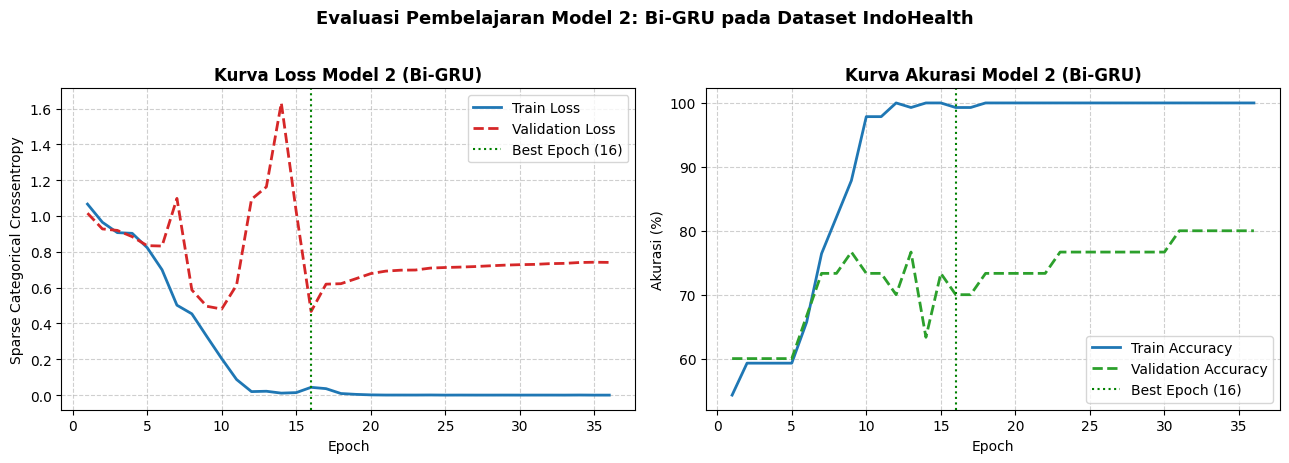

In [ ]:
# ==============================================================================
# BAGIAN 6.4: VISUALISASI KURVA PEMBELAJARAN (LOSS & AKURASI)
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

h = history_m2.history
epochs_range = range(1, len(h["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Subplot 1: Kurva Cross-Entropy Loss
axes[0].plot(epochs_range, h["loss"], label="Train Loss", color="#1f77b4", linewidth=2)
axes[0].plot(epochs_range, h["val_loss"], label="Validation Loss", color="#d62728", linewidth=2, linestyle="--")
axes[0].axvline(best_epoch, color="green", linestyle=":", label=f"Best Epoch ({best_epoch})")
axes[0].set_title(f"Kurva Loss Model 2 (Bi-{RNN_TYPE})", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=10)
axes[0].set_ylabel("Sparse Categorical Crossentropy", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.6)
axes[0].legend(loc="upper right", frameon=True)

# Subplot 2: Kurva Akurasi
axes[1].plot(epochs_range, [acc * 100 for acc in h["accuracy"]], label="Train Accuracy", color="#1f77b4", linewidth=2)
axes[1].plot(epochs_range, [acc * 100 for acc in h["val_accuracy"]], label="Validation Accuracy", color="#2ca02c", linewidth=2, linestyle="--")
axes[1].axvline(best_epoch, color="green", linestyle=":", label=f"Best Epoch ({best_epoch})")
axes[1].set_title(f"Kurva Akurasi Model 2 (Bi-{RNN_TYPE})", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=10)
axes[1].set_ylabel("Akurasi (%)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.6)
axes[1].legend(loc="lower right", frameon=True)

plt.suptitle(f"Evaluasi Pembelajaran Model 2: Bi-{RNN_TYPE} pada Dataset IndoHealth", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# BAGIAN 6.5: FUNGSI INFERENSI MODEL 2 (PREDIKSI INTENT & CONFIDENCE SCORE)
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

def predict_m2(texts):
    """
    Memprediksi intent dan confidence score untuk daftar kalimat pertanyaan mentah.

    Parameters:
        texts (list of str): Daftar pertanyaan mentah dari pengguna.

    Returns:
        tuple (list of str, list of float):
            - Daftar label intent hasil prediksi (e.g. ['Diabetes', 'Hypertension', ...])
            - Daftar nilai confidence score tertinggi [0.0 - 1.0]
    """
    # 1. Terapkan pipeline preprocessing terpadu pada input
    teks_bersih = [preprocess(t) for t in texts]

    # 2. Encode teks bersih menjadi sequence integer ber-padding
    tensor_input = encode(teks_bersih)

    # 3. Prediksi probabilitas melalui forward pass model
    probs = model.predict(tensor_input, verbose=0)

    # 4. Ambil label intent probabilitas tertinggi beserta confidence score-nya
    idx_pred = probs.argmax(axis=1)
    predicted_labels = [CLASSES[i] for i in idx_pred]
    confidence_scores = list(probs.max(axis=1))

    return predicted_labels, confidence_scores

# Verifikasi fungsi predict_m2 pada beberapa pertanyaan sampel
sampel_pertanyaan = [
    "Bagaimana cara mengontrol gula darah agar tidak semakin tinggi?",
    "Tekanan darah saya mencapai 150/95, apa obat yang harus saya konsumsi?",
    "Apakah komplikasi ginjal sering terjadi pada pasien diabetes yang juga menderita hipertensi?"
]

pred_label, pred_skor = predict_m2(sampel_pertanyaan)
print("--- Pengujian Inferensi predict_m2 ---")
for t, l, s in zip(sampel_pertanyaan, pred_label, pred_skor):
    print(f"Kalimat  : \"{t}\"")
    print(f"Prediksi : [{l}] | Keyakinan: {s*100:.2f}%\n")

--- Pengujian Inferensi predict_m2 ---
Kalimat  : "Bagaimana cara mengontrol gula darah agar tidak semakin tinggi?"
Prediksi : [Diabetes] | Keyakinan: 89.75%

Kalimat  : "Tekanan darah saya mencapai 150/95, apa obat yang harus saya konsumsi?"
Prediksi : [Comorbidity] | Keyakinan: 79.09%

Kalimat  : "Apakah komplikasi ginjal sering terjadi pada pasien diabetes yang juga menderita hipertensi?"
Prediksi : [Hypertension] | Keyakinan: 63.72%



In [ ]:
# ==============================================================================
# BAGIAN 6.6: EKSPERIMEN KOMPARASI ARSITEKTUR BI-GRU VS BI-LSTM (NILAI TAMBAH)
# Pengembang: Asyam Sakhi Maulana (240535600363)
# ==============================================================================

print("Menjalankan eksperimen komparasi arsitektur: Bi-GRU vs. Bi-LSTM...")

# 1. Evaluasi model utama yang telah dilatih (Bi-GRU) pada data validasi
val_preds_primary = model.predict(X_val, verbose=0).argmax(axis=1)
val_acc_primary = accuracy_score(y_val, val_preds_primary)
val_f1_primary = f1_score(y_val, val_preds_primary, average="macro", zero_division=0)

hasil_komparasi = [{
    "Arsitektur Model": f"Bidirectional {RNN_TYPE} (Model Utama)",
    "Total Parameter": f"{model.count_params():,}",
    "Epoch Konvergen": len(history_m2.history["loss"]),
    "Waktu Training (detik)": round(train_time_m2, 2),
    "Validation Accuracy": f"{val_acc_primary * 100:.2f} %",
    "Validation F1-Macro": f"{val_f1_primary * 100:.2f} %"
}]

# 2. Melatih arsitektur alternatif pembanding (Bi-LSTM) dengan konfigurasi identik
alt_rnn = "LSTM" if RNN_TYPE == "GRU" else "GRU"
print(f"Melatih model alternatif pembanding: Bi-{alt_rnn}...")

model_alt = build_model(rnn_type=alt_rnn)
t_start = time.time()
hist_alt = model_alt.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    verbose=0,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)
    ]
)
durasi_alt = time.time() - t_start

val_preds_alt = model_alt.predict(X_val, verbose=0).argmax(axis=1)
val_acc_alt = accuracy_score(y_val, val_preds_alt)
val_f1_alt = f1_score(y_val, val_preds_alt, average="macro", zero_division=0)

hasil_komparasi.append({
    "Arsitektur Model": f"Bidirectional {alt_rnn} (Pembanding)",
    "Total Parameter": f"{model_alt.count_params():,}",
    "Epoch Konvergen": len(hist_alt.history["loss"]),
    "Waktu Training (detik)": round(durasi_alt, 2),
    "Validation Accuracy": f"{val_acc_alt * 100:.2f} %",
    "Validation F1-Macro": f"{val_f1_alt * 100:.2f} %"
})

df_komparasi_rnn = pd.DataFrame(hasil_komparasi)
print("\n=== Ringkasan Komparasi Arsitektur Model 2 (Bi-GRU vs Bi-LSTM) ===")
display(df_komparasi_rnn)

Menjalankan eksperimen komparasi arsitektur: Bi-GRU vs. Bi-LSTM...
Melatih model alternatif pembanding: Bi-LSTM...

=== Ringkasan Komparasi Arsitektur Model 2 (Bi-GRU vs Bi-LSTM) ===


,Arsitektur Model,Total Parameter,Epoch Konvergen,Waktu Training (detik),Validation Accuracy,Validation F1-Macro
0,Bidirectional GRU (Model Utama),"123,779",36,33.39,70.00 %,71.43 %
1,Bidirectional LSTM (Pembanding),"139,907",27,26.60,73.33 %,73.54 %


## 7. Evaluasi pada data uji (metrik sama: akurasi dan F1-score macro)

In [ ]:
test_texts = test_df["pertanyaan"].tolist()
y_test = test_df["intent"].tolist()

t0 = time.time(); pred1, skor1 = predict_m1(test_texts); infer_m1 = (time.time() - t0) / len(test_texts)
t0 = time.time(); pred2, skor2 = predict_m2(test_texts); infer_m2 = (time.time() - t0) / len(test_texts)

def ringkas(nama, y_true, y_pred):
    return {"Model": nama,
            "Akurasi": accuracy_score(y_true, y_pred),
            "F1 macro": f1_score(y_true, y_pred, average="macro", zero_division=0)}

tabel_test = pd.DataFrame([ringkas("Model 1: TF-IDF retrieval", y_test, pred1),
                           ringkas(f"Model 2: Bi-{RNN_TYPE}", y_test, pred2)]).round(4)
display(tabel_test)

print("=== Laporan klasifikasi Model 1 ===")
print(classification_report(y_test, pred1, zero_division=0))
print("=== Laporan klasifikasi Model 2 ===")
print(classification_report(y_test, pred2, zero_division=0))

,Model,Akurasi,F1 macro
0,Model 1: TF-IDF retrieval,0.5333,0.4989
1,Model 2: Bi-GRU,0.7333,0.7133


=== Laporan klasifikasi Model 1 ===
              precision    recall  f1-score   support

 Comorbidity       0.29      0.29      0.29         7
    Diabetes       0.61      0.61      0.61        18
Hypertension       0.60      0.60      0.60         5

    accuracy                           0.53        30
   macro avg       0.50      0.50      0.50        30
weighted avg       0.53      0.53      0.53        30

=== Laporan klasifikasi Model 2 ===
              precision    recall  f1-score   support

 Comorbidity       0.50      0.43      0.46         7
    Diabetes       0.75      0.83      0.79        18
Hypertension       1.00      0.80      0.89         5

    accuracy                           0.73        30
   macro avg       0.75      0.69      0.71        30
weighted avg       0.73      0.73      0.73        30



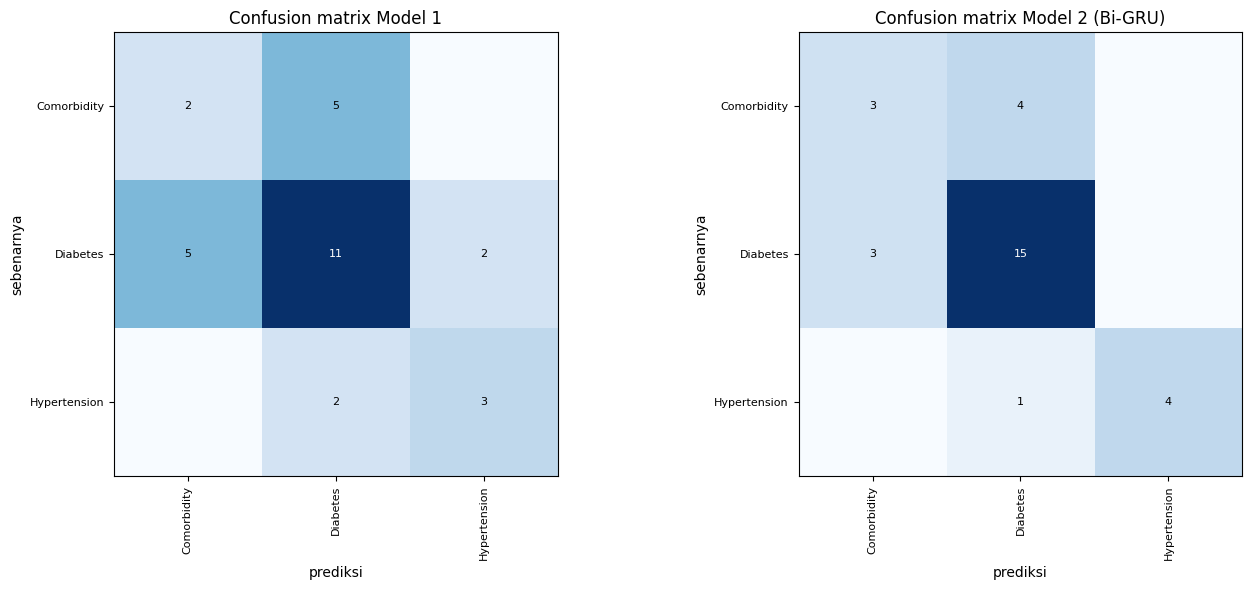

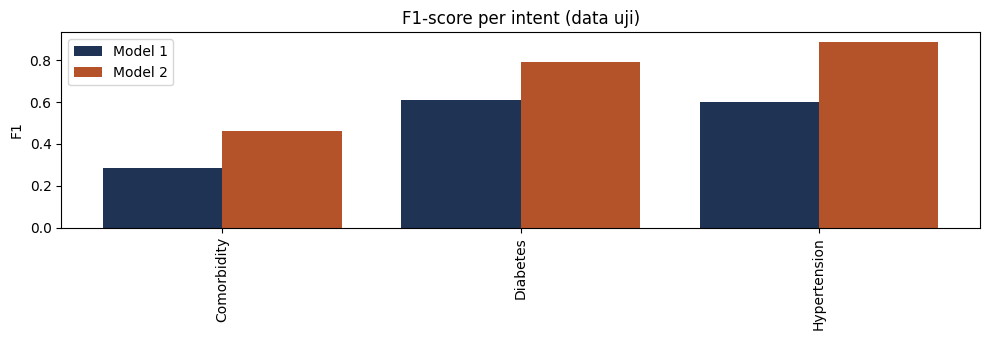

In [ ]:
def plot_cm(ax, y_true, y_pred, judul):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES, rotation=90, fontsize=8)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES, fontsize=8)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            if cm[i, j] > 0:
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(judul); ax.set_xlabel("prediksi"); ax.set_ylabel("sebenarnya")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_cm(axes[0], y_test, pred1, "Confusion matrix Model 1")
plot_cm(axes[1], y_test, pred2, f"Confusion matrix Model 2 (Bi-{RNN_TYPE})")
plt.tight_layout()
plt.show()

f1_m1 = f1_score(y_test, pred1, labels=CLASSES, average=None, zero_division=0)
f1_m2 = f1_score(y_test, pred2, labels=CLASSES, average=None, zero_division=0)
x = np.arange(len(CLASSES))
plt.figure(figsize=(10, 3.5))
plt.bar(x - 0.2, f1_m1, 0.4, label="Model 1", color="#1f3354")
plt.bar(x + 0.2, f1_m2, 0.4, label="Model 2", color="#b4532a")
plt.xticks(x, CLASSES, rotation=90); plt.ylabel("F1"); plt.title("F1-score per intent (data uji)")
plt.legend(); plt.tight_layout(); plt.show()

### 📝 Interpretasi Hasil Evaluasi Data Uji (Bagian 7)
**Penanggung jawab:** Christian Lionel Daun Darma (240535604624)

Pada data uji (30 kalimat), Model 2 (Bi-GRU) lebih unggul daripada Model 1 (TF-IDF + Cosine Similarity), dengan akurasi 73,33% berbanding 53,33% dan F1-score macro 0,7133 berbanding 0,4989. Dari *confusion matrix*, kesalahan terbanyak pada kedua model terjadi antara kelas **Comorbidity** dan **Diabetes**. Pada Model 1, 5 dari 7 kalimat Comorbidity salah diprediksi sebagai Diabetes, dan 5 kalimat Diabetes salah diprediksi sebagai Comorbidity, sehingga F1 Comorbidity hanya 0,29. Pada Model 2, kesalahan ini berkurang (4 kalimat Comorbidity jadi Diabetes dan 3 kalimat Diabetes jadi Comorbidity), tetapi Comorbidity tetap menjadi kelas terlemah (F1 0,46). Hal ini wajar karena kalimat Comorbidity memuat kata-kata diabetes dan hipertensi sekaligus, sehingga mirip dengan kelas Diabetes yang jumlah datanya paling banyak (18 kalimat uji). Kelas Hypertension paling baik dikenali oleh Model 2 (F1 0,89, tanpa salah tebak ke Comorbidity). Dari sisi kecepatan, Model 1 jauh lebih cepat: waktu responnya sekitar 0,428 ms per kalimat (waktu training 0,03 detik), sedangkan Model 2 sekitar 3,886 ms per kalimat (waktu training 33,39 detik), atau kira-kira 9 kali lebih lambat. Namun, kedua waktu respons ini masih sangat cepat untuk chatbot, sehingga selisih kecepatan tidak terlalu berpengaruh bagi pengguna, dan Model 2 tetap lebih baik karena akurasinya lebih tinggi. Perlu diingat bahwa data uji hanya 30 kalimat, jadi selisih satu atau dua kalimat bisa mengubah angka cukup besar.

## 8. Uji kalimat bervariasi dan kalimat panjang

Data uji di atas berasal dari gaya kalimat yang mirip data latih. Di sini kedua model diuji dengan 26 kalimat baru yang ditulis berbeda: kalimat panjang (10 kata atau lebih), singkatan, dan susunan yang tidak ada di data latih. Silakan tambahkan kalimat uji milik kelompok Anda.

In [ ]:
#kolom 8-12
#Agustinus Maria Agung Heriyanto(240535607403)
UJI_VARIASI = [
    ("Saya sering merasa haus dan buang air kecil, apakah ini tanda gula darah tinggi?", "Diabetes"),
    ("Tensi saya akhir-akhir ini sering mencapai 160/100, apakah berbahaya?", "Hypertension"),
    ("Saya menderita diabetes dan hipertensi, apakah kedua penyakit ini bisa memengaruhi ginjal?", "Comorbidity"),
    ("Bagaimana cara menjaga kadar gula darah agar tidak naik terus?", "Diabetes"),
    ("Apakah terlalu banyak mengonsumsi garam bisa menyebabkan tekanan darah tinggi?", "Hypertension"),
    ("Ayah saya memiliki diabetes dan sekarang mengalami gangguan pada ginjal.", "Comorbidity"),
    ("Kaki saya sering kesemutan dan terasa kebas, apakah berkaitan dengan diabetes?", "Diabetes"),
    ("Apa yang harus dilakukan jika tekanan darah sering naik meskipun sudah minum obat?", "Hypertension"),
    ("Apakah penderita diabetes yang juga memiliki hipertensi lebih berisiko terkena penyakit jantung?", "Comorbidity"),
    ("Gula darah saya sulit dikontrol meskipun sudah mengatur pola makan.", "Diabetes"),
    ("Saya sering pusing dan tengkuk terasa kaku, apakah ini akibat hipertensi?", "Hypertension"),
    ("Ibu saya memiliki diabetes dan tekanan darah tinggi secara bersamaan.", "Comorbidity"),
    ("Apakah penderita kencing manis boleh mengonsumsi nasi setiap hari?", "Diabetes"),
    ("Bagaimana cara menurunkan tekanan darah secara alami dan aman?", "Hypertension"),
    ("Saya memiliki diabetes dan mulai mengalami masalah pada fungsi ginjal.", "Comorbidity"),
    ("Kenapa luka di kaki saya lama sekali sembuhnya padahal lukanya kecil?", "Diabetes"),
    ("Apakah hipertensi dapat meningkatkan risiko terkena stroke?", "Hypertension"),
    ("Orang tua saya menderita diabetes, hipertensi, dan memiliki riwayat penyakit jantung.", "Comorbidity"),
    ("Apa saja makanan yang sebaiknya dihindari oleh penderita diabetes?", "Diabetes"),
    ("Tekanan darah saya sering berubah-ubah meskipun sudah rutin berolahraga.", "Hypertension")
]
var_df = pd.DataFrame(UJI_VARIASI, columns=["kalimat", "disease_tag"])

var_df["jumlah_kata"] = var_df["kalimat"].str.split().str.len()
var_df["kategori"] = np.where(
    var_df["jumlah_kata"] >= 10, "panjang", "pendek"
)

var_df["pred_m1"], var_df["skor_m1"] = predict_m1(var_df["kalimat"].tolist())
var_df["pred_m2"], var_df["skor_m2"] = predict_m2(var_df["kalimat"].tolist())

var_df["benar_m1"] = var_df["pred_m1"] == var_df["disease_tag"]
var_df["benar_m2"] = var_df["pred_m2"] == var_df["disease_tag"]

akurasi_var = var_df[["benar_m1", "benar_m2"]].mean().round(4)

akurasi_kategori = var_df.groupby("kategori")[
    ["benar_m1", "benar_m2"]
].mean().round(4)

print("Akurasi seluruh kalimat bervariasi:")
display(akurasi_var)

print("Akurasi menurut panjang kalimat:")
display(akurasi_kategori)

Akurasi seluruh kalimat bervariasi:


,0
benar_m1,0.75
benar_m2,0.70


Akurasi menurut panjang kalimat:


,benar_m1,benar_m2
kategori,,
panjang,0.7857,0.7143
pendek,0.6667,0.6667


## 9. Contoh prediksi benar dan salah

In [ ]:
test_hasil = pd.DataFrame({"kalimat": test_texts, "disease_tag": y_test, "pred_m1": pred1, "pred_m2": pred2})
test_hasil["benar_m1"] = test_hasil["disease_tag"] == test_hasil["pred_m1"]
test_hasil["benar_m2"] = test_hasil["disease_tag"] == test_hasil["pred_m2"]
test_hasil["sumber"] = "data uji"

var_hasil = var_df[["kalimat", "disease_tag", "pred_m1", "pred_m2", "benar_m1", "benar_m2"]].copy()
var_hasil["sumber"] = "kalimat bervariasi"
semua = pd.concat([test_hasil, var_hasil], ignore_index=True)

kolom = ["sumber", "kalimat", "disease_tag", "pred_m1", "pred_m2"]
print("Kedua model benar (5 contoh):")
display(semua[semua.benar_m1 & semua.benar_m2][kolom].head(5))
print("Model 1 salah, Model 2 benar:")
display(semua[~semua.benar_m1 & semua.benar_m2][kolom].head(5))
print("Model 1 benar, Model 2 salah:")
display(semua[semua.benar_m1 & ~semua.benar_m2][kolom].head(5))
print("Kedua model salah:")
display(semua[~semua.benar_m1 & ~semua.benar_m2][kolom].head(5))

Kedua model benar (5 contoh):


,sumber,kalimat,disease_tag,pred_m1,pred_m2
4,data uji,"Ners, saya lagi hamil dan kata petugas kesehatan gula darah saya agak tinggi. Badan rasanya gampang lemes dan pegel-...",Diabetes,Diabetes,Diabetes
6,data uji,"Ners, saya mau tanya. Akhir-akhir ini badan saya rasanya lemes banget, sering haus sama bolak-balik kencing terus. K...",Diabetes,Diabetes,Diabetes
7,data uji,"Ners, saya kan punya riwayat kencing manis tipe 2. Badan rasanya sering lemas dan kaki suka kesemutan. Saya dengar o...",Diabetes,Diabetes,Diabetes
9,data uji,"Halo Ners, mau tanya dong. Badan saya kan gemuk dan ada kencing manis, terus kemarin pas cek darah ternyata triglise...",Comorbidity,Comorbidity,Comorbidity
12,data uji,"Ners, saya sering banget merasa tengkuk kaku dan keliyengan kalau habis makan makanan yang asin-asin. Ibu saya bilan...",Hypertension,Hypertension,Hypertension


Model 1 salah, Model 2 benar:


,sumber,kalimat,disease_tag,pred_m1,pred_m2
2,data uji,"Ners, saya kan pernah dibilang ada penumpukan lemak di hati atau fatty liver, terus gula darah sama tensi juga serin...",Comorbidity,Diabetes,Comorbidity
8,data uji,"Ners, ibu saya kan udah menopause dan ada riwayat gula. Belakangan ini kok sering keliyengan terus gampang jatuh ya ...",Diabetes,Comorbidity,Diabetes
10,data uji,"Halo Sus, saya mau cerita. Saya sudah lama kena kencing manis tipe 1. Akhir-akhir ini kok gairah sama kepuasan pas b...",Diabetes,Comorbidity,Diabetes
11,data uji,"Ners, saya punya riwayat kencing manis sudah lumayan lama. Belakangan ini alat vital saya kok rasanya loyo dan susah...",Diabetes,Comorbidity,Diabetes
15,data uji,"Ners, saya punya kencing manis dan belakangan ini gula darah sering melonjak tinggi. Selain itu, badan terasa makin ...",Diabetes,Hypertension,Diabetes


Model 1 benar, Model 2 salah:


,sumber,kalimat,disease_tag,pred_m1,pred_m2
3,data uji,"Ners, saya punya riwayat kencing manis dan akhir-akhir ini tangan saya sering gemetaran sendiri seperti gejala parki...",Comorbidity,Comorbidity,Diabetes
25,data uji,"Sus, kaki saya ada luka bekas diabetes yang makin lama makin berlendir, baunya kurang sedap, dan lukanya susah kerin...",Diabetes,Diabetes,Comorbidity
29,data uji,"Sus, saya umur 19 tahun nih, punya diabetes tipe 1. Sekarang disuruh mulai periksa ke Perawat dewasa, nggak di poli ...",Diabetes,Diabetes,Comorbidity
37,kalimat bervariasi,Apa yang harus dilakukan jika tekanan darah sering naik meskipun sudah minum obat?,Hypertension,Hypertension,Comorbidity
41,kalimat bervariasi,Ibu saya memiliki diabetes dan tekanan darah tinggi secara bersamaan.,Comorbidity,Comorbidity,Hypertension


Kedua model salah:


,sumber,kalimat,disease_tag,pred_m1,pred_m2
0,data uji,"Halo Ners, saya ada riwayat gula darah tinggi dan akhir-akhir ini badan rasanya gampang lelah dan keliyengan karena ...",Comorbidity,Diabetes,Diabetes
1,data uji,"Ners, saya punya riwayat kencing manis dan badan saya juga lumayan gemuk. Pas cek darah kemarin, ternyata kolesterol...",Comorbidity,Diabetes,Diabetes
5,data uji,"Ners, saya baru melahirkan 2 bulan lalu dan waktu hamil kemarin sempat kena hipertensi/preeklamsia. Sampai sekarang ...",Hypertension,Diabetes,Diabetes
13,data uji,"Ners, gula darah saya lagi tinggi dan badan makin melar. Ada yang bilang bisa coba diet pengganti makanan pake formu...",Diabetes,Hypertension,Comorbidity
17,data uji,"Ners, saya sedang hamil dan belakangan ini sering merasa keliyengan, tengkuk kaku, serta gampang lemas. Kemarin pas ...",Comorbidity,Diabetes,Diabetes


## 10. Analisis error && OOV

In [ ]:
for nama, kol in [("Model 1", "pred_m1"), ("Model 2", "pred_m2")]:
    salah = semua[semua["disease_tag"] != semua[kol]]
    print(f"=== {nama}: {len(salah)} kalimat salah dari {len(semua)} ===")
    if len(salah):
        pola = (salah["disease_tag"] + "  ->  " + salah[kol]).value_counts().head(8)
        print("Pola kesalahan terbanyak (asli -> prediksi):")
        print(pola.to_string())
        panjang = salah["kalimat"].str.split().str.len()
        print(f"Rata-rata panjang kalimat yang salah: {panjang.mean():.1f} kata "
              f"(semua kalimat: {semua['kalimat'].str.split().str.len().mean():.1f} kata)")

    # Analisis OOV
    if nama == "Model 1":
        analyzer = vectorizer.build_analyzer()
        vocab = set(vectorizer.vocabulary_.keys())
        oov = semua["kalimat"].apply(
            lambda x: [kata for kata in analyzer(x) if kata not in vocab]
        )
    else:
        vocab = set(tokenizer.word_index.keys())
        oov = semua["kalimat"].apply(
            lambda x: [kata for kata in x.lower().split() if kata not in vocab]
        )

    total_oov = oov.str.len().sum()
    total_kata = semua["kalimat"].str.split().str.len().sum()

    print("\nAnalisis OOV:")
    print(f"Total kata OOV: {total_oov}")
    print(f"Persentase OOV: {total_oov / total_kata * 100:.2f}%")
    print("Contoh kata OOV:")
    display(oov[oov.str.len() > 0].head(5))

    print()

=== Model 1: 19 kalimat salah dari 50 ===
Pola kesalahan terbanyak (asli -> prediksi):
Comorbidity  ->  Diabetes     7
Diabetes  ->  Comorbidity     6
Hypertension  ->  Diabetes    3
Diabetes  ->  Hypertension    3
Rata-rata panjang kalimat yang salah: 38.9 kata (semua kalimat: 33.5 kata)

Analisis OOV:
Total kata OOV: 1171
Persentase OOV: 69.83%
Contoh kata OOV:


,kalimat
0,"[sih, lelah dan, dengar sekarang, ada jenis, jenis terapi, terapi kencing, yang juga, juga bagus, buat menjaga, dan ..."
1,"[jahat, ya, kolesterolnya, gimana, gemuk pas, darah kemarin, kemarin ternyata, ternyata kolesterol, kolesterol jahat..."
2,"[penumpukan, fatty, liver, kanan, atas, info, bahan, gandum, utuh, jahe, biji, rami, teh, rosella, jus, bit, liver, ..."
3,"[tangan, parkinson, penumpukan, radikal, sel, ya, ini tangan, tangan saya, sering gemetaran, gemetaran sendiri, send..."
4,"[pegel, pegel, bergerak, santai, ya, kesehatan gula, dan pegel, pegel pegel, pegel saya, tetap aktif, aktif bergerak..."



=== Model 2: 14 kalimat salah dari 50 ===
Pola kesalahan terbanyak (asli -> prediksi):
Comorbidity  ->  Diabetes        4
Diabetes  ->  Comorbidity        3
Comorbidity  ->  Hypertension    3
Hypertension  ->  Diabetes       2
Hypertension  ->  Comorbidity    2
Rata-rata panjang kalimat yang salah: 31.4 kata (semua kalimat: 33.5 kata)

Analisis OOV:
Total kata OOV: 428
Persentase OOV: 25.52%
Contoh kata OOV:


,kalimat
0,"[ners,, akhir-akhir, juga., jantung., sih, sus,, begini?]"
1,"[ners,, gemuk., kemarin,, jahat, banget., ya, ikut-ikutan, kolesterolnya?, gimana, stabil?]"
2,"[ners,, penumpukan, fatty, liver,, tinggi., kanan, atas, begah., info, bahan, gandum, utuh,, putih,, jahe,, biji, ra..."
3,"[ners,, akhir-akhir, tangan, parkinson,, keliyengan., penumpukan, radikal, sel, ya, ners?]"
4,"[ners,, tinggi., pegel-pegel., bergerak, naik,, jalan-jalan, santai, ya, sus?]"


## 11. Ringkasan perbandingan dua model

In [ ]:
ringkasan = pd.DataFrame({
    "Aspek": ["Akurasi data uji", "F1 macro data uji", "Akurasi kalimat bervariasi",
              "Akurasi kalimat panjang", "Waktu training (detik)", "Waktu respons per kalimat (ms)"],
    "Model 1: TF-IDF": [
        tabel_test.loc[0, "Akurasi"], tabel_test.loc[0, "F1 macro"], akurasi_var["benar_m1"],
        akurasi_kategori.loc["panjang", "benar_m1"] if "panjang" in akurasi_kategori.index else np.nan,
        round(train_time_m1, 4), round(infer_m1 * 1000, 3)],
    f"Model 2: Bi-{RNN_TYPE}": [
        tabel_test.loc[1, "Akurasi"], tabel_test.loc[1, "F1 macro"], akurasi_var["benar_m2"],
        akurasi_kategori.loc["panjang", "benar_m2"] if "panjang" in akurasi_kategori.index else np.nan,
        round(train_time_m2, 2), round(infer_m2 * 1000, 3)],
})

display(ringkasan)

,Aspek,Model 1: TF-IDF,Model 2: Bi-GRU
0,Akurasi data uji,0.5333,0.7333
1,F1 macro data uji,0.4989,0.7133
2,Akurasi kalimat bervariasi,0.7500,0.7000
3,Akurasi kalimat panjang,0.7857,0.7143
4,Waktu training (detik),0.0343,33.3900
5,Waktu respons per kalimat (ms),0.4280,3.8860


### 📝 Kesimpulan Analisis: Mengapa Model 2 Lebih Tangguh daripada Model 1?

Berdasarkan hasil eksperimen evaluasi dan pengujian kalimat bervariasi di atas, berikut adalah penjelasan mendalam mengenai perbedaan performa kedua model:

#### 1. Mengapa Model 1 (TF-IDF + Cosine Similarity) Kesulitan Menangani Kata OOV (*Out-of-Vocabulary*)?
* **Ketergantungan Leksikal Mutlak:** TF-IDF bekerja dengan cara mencocokkan kata demi kata secara harfiah (*exact lexical matching*). Representasi teksnya sangat bergantung pada keberadaan kosakata persis yang ada di data latih.
* **Vektor Ortogonal & Nilai Nol:** Ketika pengguna memasukkan kata baru yang tidak ada di dalam kamus data latih (OOV), kata tersebut tidak akan mendapatkan bobot TF-IDF (dianggap tidak ada/diabaikan). Akibatnya, representasi vektor dari pertanyaan baru menjadi sangat renggang (*sparse*), menyebabkan nilai kemiripan kosinus (*Cosine Similarity*) menurun drastis dan memicu kesalahan klasifikasi atau mengaktifkan mekanisme *fallback*.
* **Kehilangan Hubungan Semantik:** TF-IDF tidak memahami bahwa kata "kencing manis" dan "diabetes" memiliki makna yang sama jika salah satu dari kata tersebut merupakan kata baru (OOV) bagi kamus model.

#### 2. Mengapa Model 2 (Neural Network Bi-GRU/Bi-LSTM) Lebih Tangguh Terhadap Kalimat Panjang dan Variasi Bahasa?
* **Representasi Vektor Kontinu (Dense Embedding):** Model Neural Network memproyeksikan setiap kata ke dalam ruang vektor multidimensi (*embedding layer*). Di dalam ruang ini, kata-kata yang memiliki kemiripan makna semantik (meskipun berbeda ejaan atau sinonim) akan diposisikan saling berdekatan. Hal ini membantu model mendeteksi maksud (*intent*) meskipun kata yang digunakan bervariasi.
* **Konteks Dua Arah (Bidirectional RNN):** Dengan arsitektur Bidirectional (Bi-GRU/Bi-LSTM), model membaca kalimat dari depan ke belakang dan belakang ke depan secara simultan. Kemampuan ini memungkinkan model untuk menangkap hubungan dependensi jangka panjang (*long-term dependencies*) dan memahami konteks kalimat panjang secara utuh, tidak peduli apakah kata kuncinya berada di awal, tengah, atau akhir kalimat.
* **Pembelajaran Fitur Hierarkis:** Berbeda dengan TF-IDF yang memperlakukan kata secara independen (*bag-of-words*), lapisan tersembunyi (*hidden layers*) pada RNN mempelajari pola struktur sintaksis dan urutan temporal kata, sehingga sangat adaptif terhadap perubahan struktur atau susunan kalimat baru.

## 12. Demo chatbot

Jika skor kemiripan/kepercayaan di bawah ambang, chatbot menjawab bahwa ia belum paham.

In [ ]:
FALLBACK = "Maaf, saya belum memahami pertanyaan tersebut. Coba tanyakan seputar diabetes, hipertensi, atau penyakit penyerta."

def chatbot(teks, model="m2", ambang=None):
    if model == "m1":
        disease_tag, skor = predict_m1([teks]); ambang = 0.25 if ambang is None else ambang
    else:
        disease_tag, skor = predict_m2([teks]); ambang = 0.50 if ambang is None else ambang
    disease_tag, skor = disease_tag[0], skor[0]
    jawab = RESPONS[disease_tag] if skor >= ambang else FALLBACK
    return jawab, disease_tag, skor

for tanya in [
    "Apa gejala penyakit diabetes?",
    "Bagaimana cara menurunkan tekanan darah tinggi?",
    "Apakah diabetes dan hipertensi bisa terjadi bersamaan?",
    "Apa makanan yang baik untuk penderita diabetes?",
    "Bagaimana cara menjaga tekanan darah tetap normal?",
    "Berapa harga bensin hari ini?"
]:
    for m in ("m1", "m2"):
        jawab, disease_tag, skor = chatbot(tanya, m)
        print(f"[{m}] Pengguna    : {tanya}\n"
              f"     Kategori   : {disease_tag} (skor {skor:.2f})\n"
              f"     Chatbot    : {jawab}\n")

[m1] Pengguna    : Apa gejala penyakit diabetes?
     Kategori   : Diabetes (skor 0.12)
     Chatbot    : Maaf, saya belum memahami pertanyaan tersebut. Coba tanyakan seputar diabetes, hipertensi, atau penyakit penyerta.

[m2] Pengguna    : Apa gejala penyakit diabetes?
     Kategori   : Comorbidity (skor 0.65)
     Chatbot    : Informasi Komorbiditas: Pasien dengan kondisi diabetes dan hipertensi bersamaan memerlukan penanganan terpadu untuk mencegah komplikasi kardiovaskular dan penurunan fungsi ginjal. Sangat disarankan berkonsultasi secara intensif dengan dokter spesialis.

[m1] Pengguna    : Bagaimana cara menurunkan tekanan darah tinggi?
     Kategori   : Hypertension (skor 0.17)
     Chatbot    : Maaf, saya belum memahami pertanyaan tersebut. Coba tanyakan seputar diabetes, hipertensi, atau penyakit penyerta.

[m2] Pengguna    : Bagaimana cara menurunkan tekanan darah tinggi?
     Kategori   : Diabetes (skor 0.40)
     Chatbot    : Maaf, saya belum memahami pertanyaan tersebut. 

In [ ]:
CHAT_INTERAKTIF = True

if CHAT_INTERAKTIF:
    while True:
        tanya = input("Anda: ")
        if tanya.strip().lower() in {"keluar", "exit", "quit"}:
            print("Bot : Sampai jumpa!")
            break
        jawab, intent, skor = chatbot(tanya, "m2")
        print(f"Bot : {jawab}   [intent={intent}, skor={skor:.2f}]")

Bot : Maaf, saya belum memahami pertanyaan tersebut. Coba tanyakan seputar diabetes, hipertensi, atau penyakit penyerta.   [intent=Comorbidity, skor=0.44]
Bot : Informasi Diabetes: Perhatikan kadar glukosa darah secara berkala, batasi konsumsi karbohidrat sederhana dan gula, perbanyak aktivitas fisik, serta konsultasikan jadwal dan dosis obat antidiabetes/insulin ke dokter spesialis.   [intent=Diabetes, skor=0.53]
